# Heart disease prediction

Can routine clinical measurements tell us whether a patient has heart disease?

**Data:** UCI Heart Disease dataset (Cleveland), 303 patients with 13 features such as age, chest pain type, resting blood pressure, cholesterol and maximum heart rate. `target = 1` means heart disease. One duplicated row is removed.

Every model below uses **the same stratified train/test split** (80/20, fixed seed). Imputation and scaling are fitted on the training data only. Models are compared with 5-fold cross-validation on the training set and scored once on the held-out test set. The shared code is in [`../src/disease_ml.py`](../src/disease_ml.py).

In [1]:
import sys
sys.path.insert(0, '../src')

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import disease_ml as dm

pd.set_option('display.precision', 3)

## 1. Data

In [2]:
X, y = dm.load_heart()
LABELS = ['No disease', 'Disease']

print(f'{X.shape[0]:,} patients, {X.shape[1]} features')
X.head()

302 patients, 13 features


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2


In [3]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
age,302.0,54.421,9.048,29.0,48.00,55.5,61.00,77.0
sex,302.0,0.682,0.466,0.0,0.00,1.0,1.00,1.0
cp,302.0,0.964,1.032,0.0,0.00,1.0,2.00,3.0
trestbps,302.0,131.603,17.563,94.0,120.00,130.0,140.00,200.0
chol,302.0,246.500,51.753,126.0,211.00,240.5,274.75,564.0
fbs,302.0,0.149,0.357,0.0,0.00,0.0,0.00,1.0
restecg,302.0,0.526,0.526,0.0,0.00,1.0,1.00,2.0
thalach,302.0,149.570,22.904,71.0,133.25,152.5,166.00,202.0
exang,302.0,0.328,0.470,0.0,0.00,0.0,1.00,1.0
oldpeak,302.0,1.043,1.161,0.0,0.00,0.8,1.60,6.2


## 2. Exploration

How balanced are the two classes, and which features move with the target?

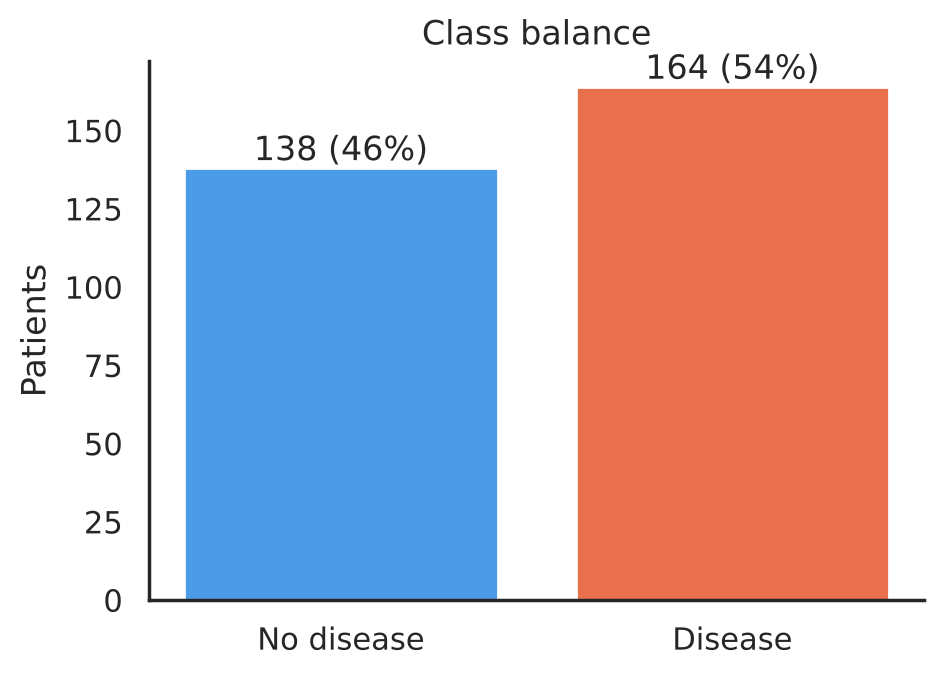

In [4]:
fig = dm.plot_class_balance(y, LABELS, 'Class balance')
dm.save(fig, 'heart_class_balance')

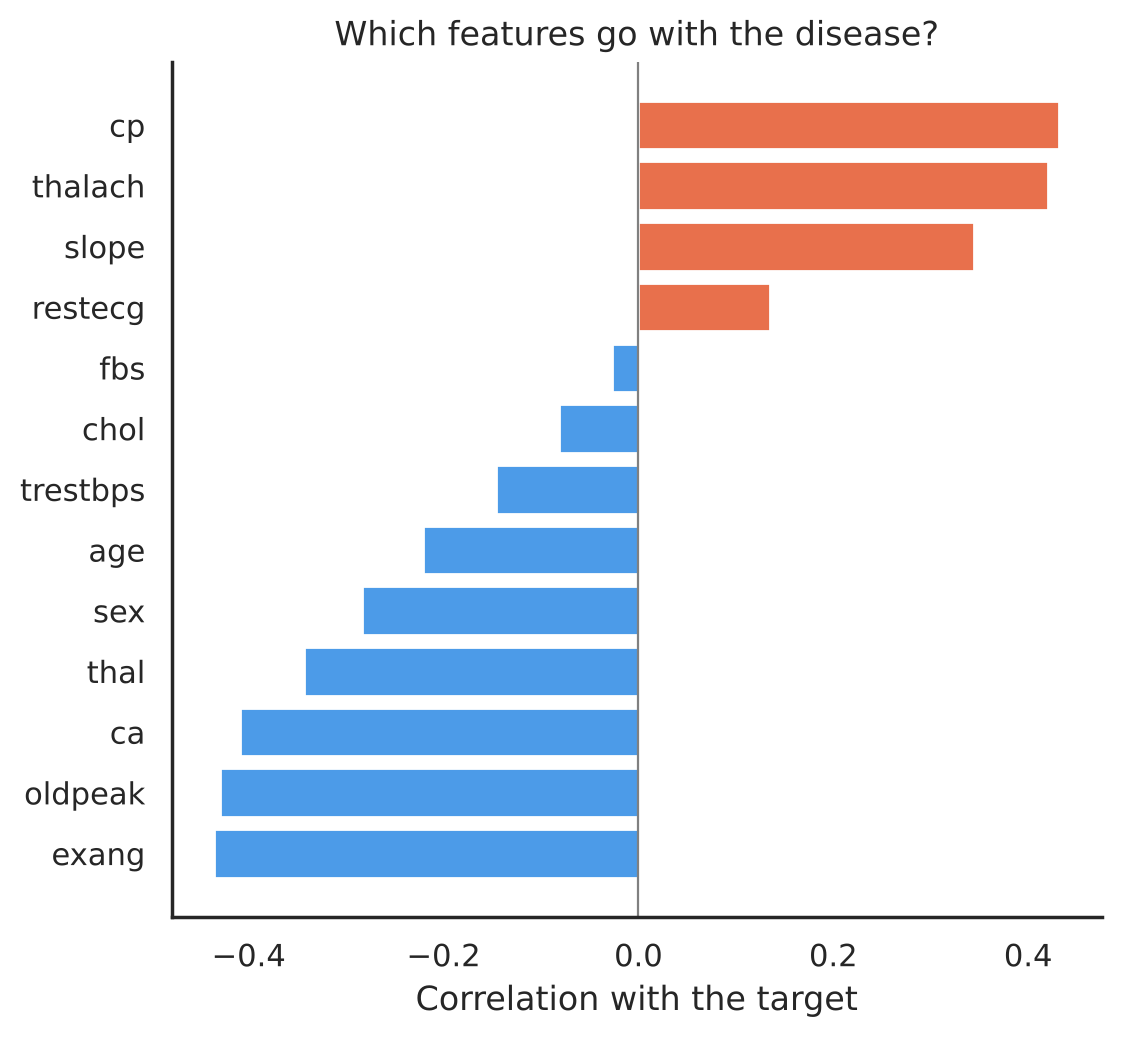

In [5]:
fig = dm.plot_correlation_with_target(X, y, 'Which features go with the disease?')
dm.save(fig, 'heart_correlation')

## 3. Classical models

In [6]:
X_train, X_test, y_train, y_test = dm.split(X, y)
models = dm.make_models(large=False, with_smote=False)

results, fitted = dm.evaluate_models(models, X_train, X_test, y_train, y_test)
results.sort_values('test_roc_auc', ascending=False)

,cv_accuracy,cv_accuracy_std,cv_roc_auc,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
model,,,,,,,,
k-nearest neighbours,0.805,0.066,0.893,0.820,0.775,0.939,0.849,0.905
Random forest,0.847,0.055,0.897,0.820,0.775,0.939,0.849,0.900
Naive Bayes,0.817,0.048,0.881,0.820,0.789,0.909,0.845,0.885
SVM (RBF kernel),0.809,0.052,0.885,0.836,0.795,0.939,0.861,0.881
Logistic regression,0.813,0.065,0.891,0.787,0.763,0.879,0.817,0.865
Decision tree,0.755,0.065,0.758,0.820,0.750,1.000,0.857,0.824
Baseline (majority class),0.544,0.004,0.500,0.541,0.541,1.000,0.702,0.500


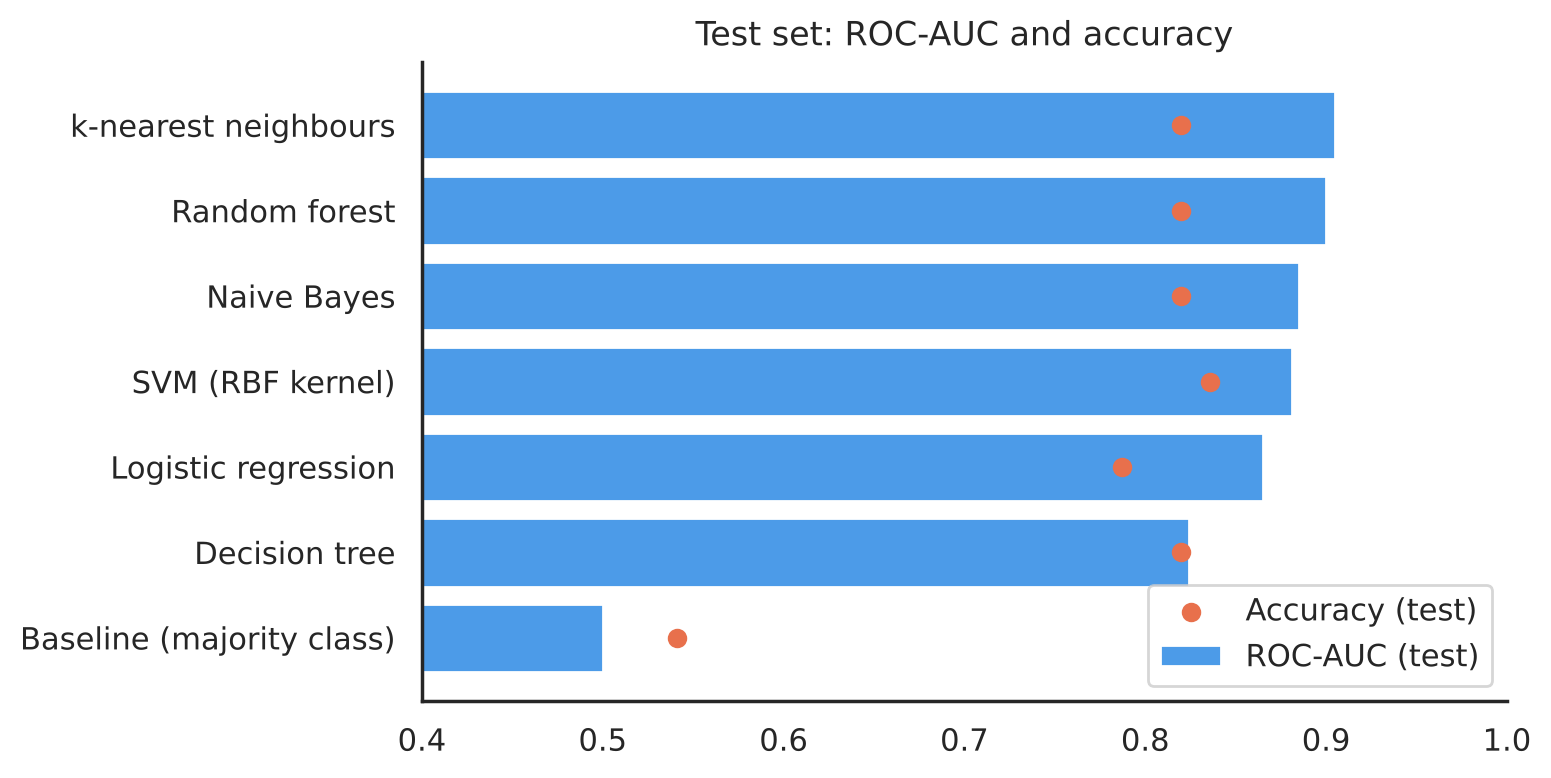

In [7]:
fig = dm.plot_model_comparison(results, 'Test set: ROC-AUC and accuracy')
dm.save(fig, 'heart_model_comparison')

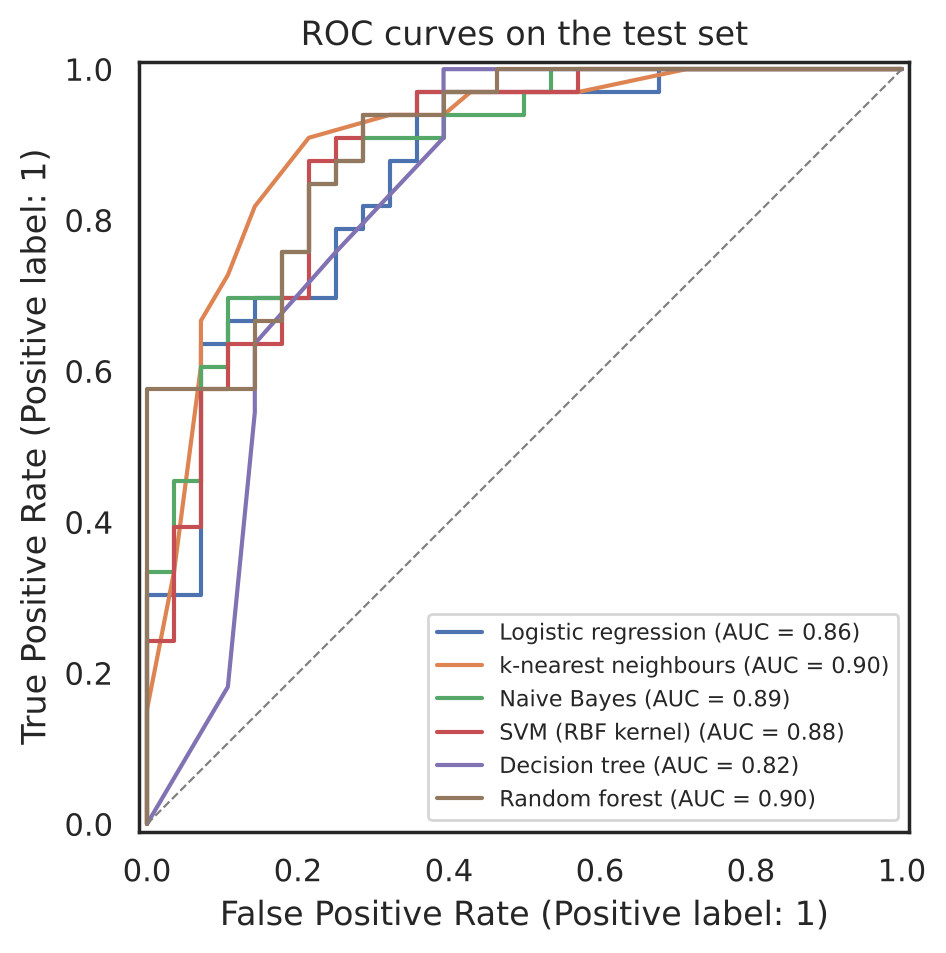

In [8]:
fig = dm.plot_roc_curves(fitted, X_test, y_test, 'ROC curves on the test set')
dm.save(fig, 'heart_roc_curves')

Best model by test ROC-AUC: k-nearest neighbours


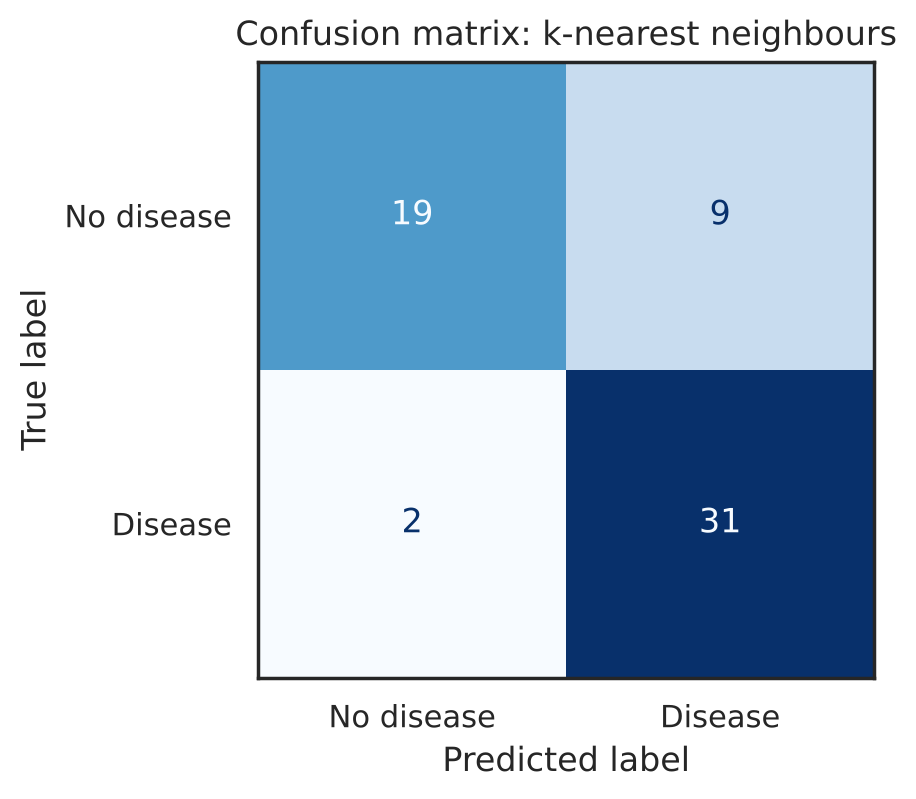

In [9]:
best = results.drop(index='Baseline (majority class)')['test_roc_auc'].idxmax()
fig = dm.plot_confusion(fitted[best], X_test, y_test, LABELS, f'Confusion matrix: {best}')
dm.save(fig, 'heart_confusion_best')
print('Best model by test ROC-AUC:', best)

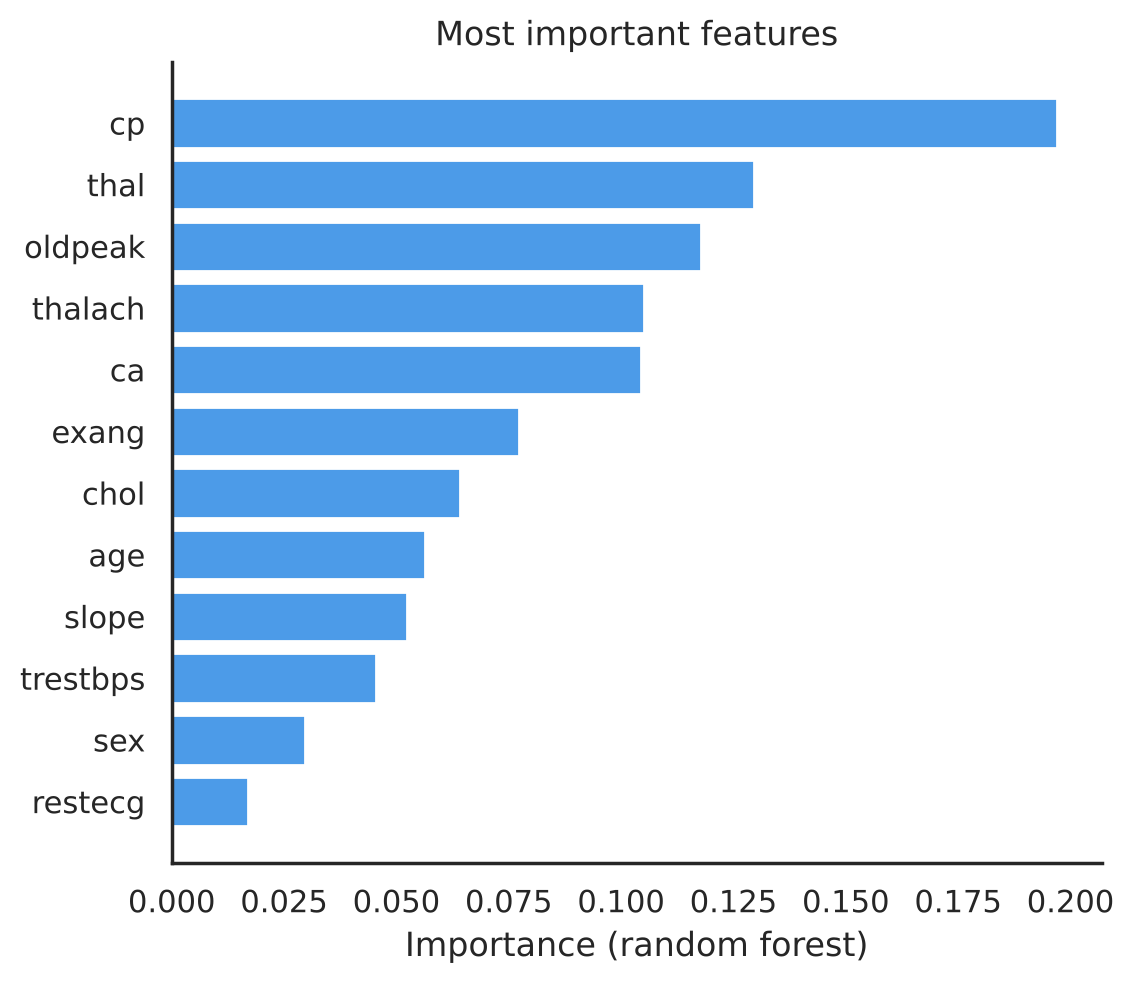

In [10]:
fig = dm.plot_feature_importance(fitted['Random forest'], X.columns, 'Most important features')
dm.save(fig, 'heart_feature_importance')

## 4. Neural network

A small Keras network (16 → 8 → 1 neurons, dropout, early stopping) trained on the same split.

I0000 00:00:1795493425.120147    8975 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795493426.408860    8975 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


test_accuracy       0.803
test_precision      0.800
test_recall         0.848
test_f1             0.824
test_roc_auc        0.865
epochs_trained    104.000
dtype: float64

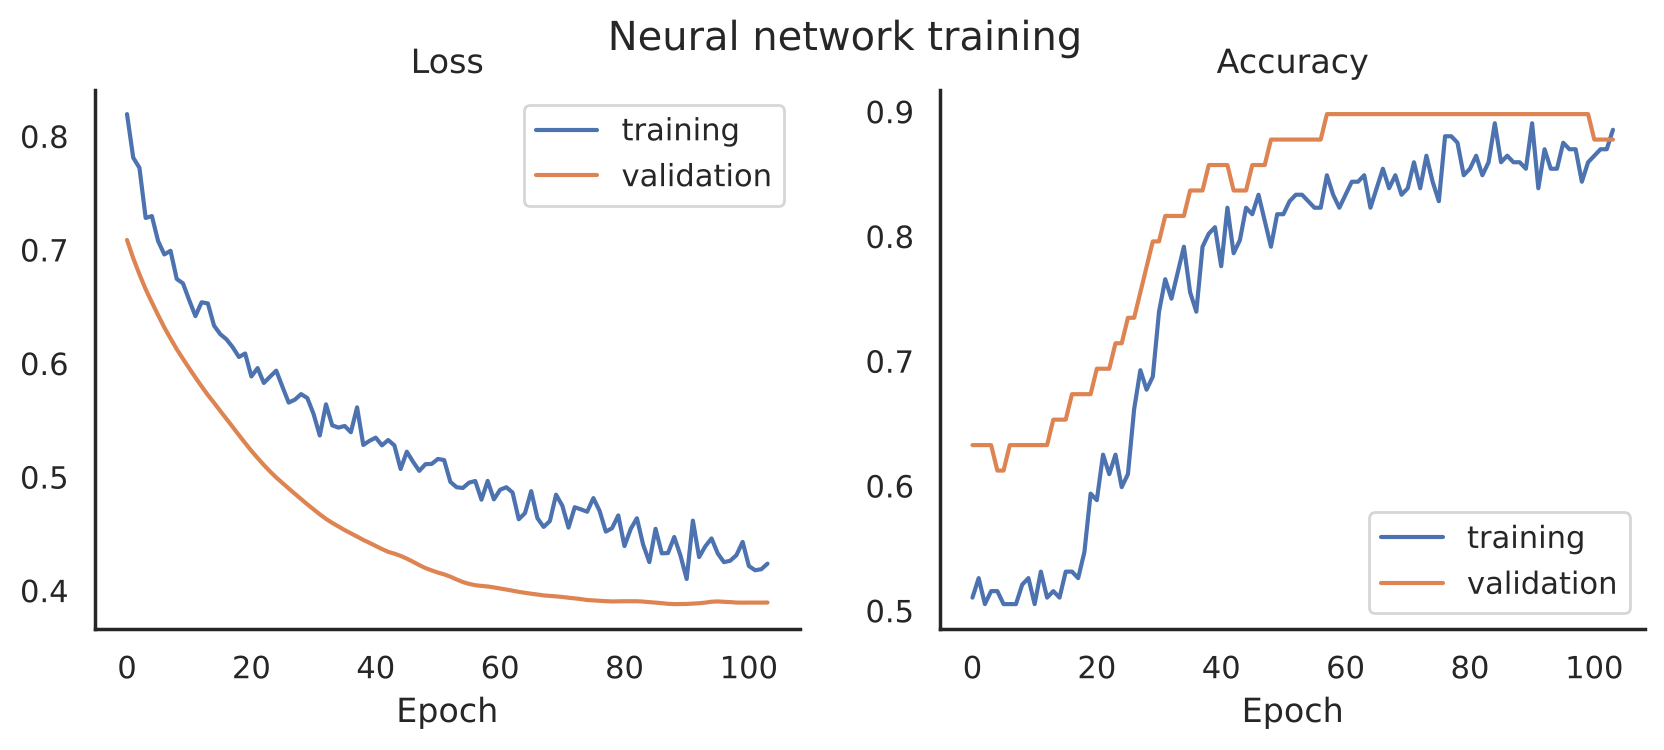

In [11]:
ann, history, ann_metrics = dm.train_ann(X_train, X_test, y_train, y_test)
fig = dm.plot_history(history, 'Neural network training')
dm.save(fig, 'heart_ann_training')
pd.Series(ann_metrics)

## 5. Summary table

In [12]:
summary = results[['cv_accuracy', 'cv_roc_auc', 'test_accuracy', 'test_recall', 'test_f1', 'test_roc_auc']].copy()
summary.loc['Neural network (Keras)'] = [None, None, ann_metrics['test_accuracy'], ann_metrics['test_recall'],
                                         ann_metrics['test_f1'], ann_metrics['test_roc_auc']]
summary = summary.sort_values('test_roc_auc', ascending=False)
dm.RESULTS_DIR.mkdir(exist_ok=True)
summary.to_csv(dm.RESULTS_DIR / 'heart_results.csv')
summary

,cv_accuracy,cv_roc_auc,test_accuracy,test_recall,test_f1,test_roc_auc
model,,,,,,
k-nearest neighbours,0.805,0.893,0.820,0.939,0.849,0.905
Random forest,0.847,0.897,0.820,0.939,0.849,0.900
Naive Bayes,0.817,0.881,0.820,0.909,0.845,0.885
SVM (RBF kernel),0.809,0.885,0.836,0.939,0.861,0.881
Neural network (Keras),NaN,NaN,0.803,0.848,0.824,0.865
Logistic regression,0.813,0.891,0.787,0.879,0.817,0.865
Decision tree,0.755,0.758,0.820,1.000,0.857,0.824
Baseline (majority class),0.544,0.500,0.541,1.000,0.702,0.500


## 6. Conclusion

- **Best models:** k-nearest neighbours and random forest reach a test ROC-AUC of about **0.90** and an accuracy of **82 %**, against 54 % for always guessing "disease". Cross-validation on the training set gives almost the same picture (ROC-AUC 0.89–0.90), so the result is not a lucky split.
- **Recall:** the best models find about **94 %** of the patients with heart disease in the test set. For a screening tool, missing a sick patient is the more serious error, so recall matters more than accuracy here.
- **Neural network:** with only 302 patients it does not beat the simpler models (ROC-AUC 0.87).
- **Most important features:** chest pain type (`cp`), thalassemia result (`thal`), ST depression (`oldpeak`) and maximum heart rate (`thalach`).
- **Caveat:** the test set has only 61 patients, so a difference of one or two patients moves accuracy by 2–3 points. Small differences between the top models are not meaningful.